# 99.7g Cost Case Study: GMRES at the Unit Operation Level

## Contents

**Tools:** CADET-Python; GMRES study helpers; residual-history, cost, plotting and parameter-sweep diagnostics.

**Python used:** Imports, helper calls, tuple unpacking and displaying diagnostic tables.

**Introduces:** Schur-complement systems, GMRES residual reduction, finite-precision limits, `SCHUR_SAFETY`, `MAX_KRYLOV`, `MAX_RESTARTS` and `GS_TYPE`.

1. Where GMRES enters the unit-operation solve
2. Residual histories and the stopping test
3. Finite precision and the cost of further reduction
4. Comparing model cost for nearly matching chromatograms
5. Measuring the four GMRES settings
6. Choosing settings and diagnosing solver-related cost

Similar chromatograms can require very different effort. This case follows the work into the linear solver and uses measured parameter sweeps to explain where the cost comes from.

## GMRES on the unit operation level

The FV unit operations that have particles do not solve their linear system
directly. They eliminate the particle unknowns into a **Schur complement** and
hand that to an **unpreconditioned GMRES**, configured by four fields that sit
in the discretization group of the unit and are easy to never think about:

```
/input/model/unit_XXX/discretization/GS_TYPE
/input/model/unit_XXX/discretization/MAX_KRYLOV
/input/model/unit_XXX/discretization/MAX_RESTARTS
/input/model/unit_XXX/discretization/SCHUR_SAFETY
```

This notebook is about what that solver does, what each of the four settings
changes, and how to choose them. It is built around a case from the forum in
which the usual values cost a factor of forty on a model that is otherwise
perfectly well posed:

> I am comparing two very similar models, one with LRM, the other one with
> LRMP. Both simulate a batch-elution process for a 2-component system with a
> linear isotherm. For validation purposes [...] rapid equilibrium,
> non-limiting film diffusion ($k_f = 1$), and no axial dispersion. While the
> LRM completes within a few seconds, the LRMP takes approximately 20 minutes
> to run under the same conditions.

It reproduces: **328 s against 2 s**. And it is the companion case to the
stiffness chapter, because the integrator is behaving perfectly throughout —
the expensive model takes *fewer* steps than the cheap one, at the same order.
Everything is happening one level below it, inside the linear solve.

The ending, up front, because it is not the ending this notebook was expected
to have. Three of the four settings are each individually worth most of the
factor on this case:

| change, one at a time | wall clock |
|---|---|
| nothing (`1e-8`, `0`, `10`, `1`) | **328 s** |
| `SCHUR_SAFETY` from `1e-8` to `1e-7` | 11.4 s |
| `MAX_KRYLOV` from `0` to `25` | 10.0 s |
| `GS_TYPE` from `1` to `0` | 12.2 s |

Every one of those returns the same answer to every digit printed. They are
not three fixes for three problems; they are three ways out of one, and the
rest of this notebook is about what that one is.

Source references are to CADET-Core at `c9742388`.

## 1. Where the GMRES is, and what it solves

A column with particles has a Jacobian with an **arrow head** structure. Write
the unknowns as bulk liquid, particle (liquid and solid), and the flux
variables that couple them:

$$
J = \begin{bmatrix}
J_0 & & J_{0,f} \\
 & J_p & J_{p,f} \\
J_{f,0} & J_{f,p} & J_f
\end{bmatrix}
$$

The diagonal blocks are cheap: $J_0$ is a banded convection-dispersion
operator, $J_p$ is block diagonal with one small block per axial cell. The
arms are sparse. Only the coupling makes the system global.

CADET exploits this with a block $LU$ factorization. Factorize $J_0$ and
$J_p$ once, forward-substitute, and what is left is one system in the flux
unknowns alone, with the **Schur complement**

$$
S \;=\; J_f \;-\; J_{f,0}\,J_0^{-1}\,J_{0,f} \;-\; J_{f,p}\,J_p^{-1}\,J_{p,f}.
$$

$S$ is small — one unknown per axial cell, component and particle type, so
$500 \times 2 \times 1 = 1000$ here against 4002 degrees of freedom in the
unit — but it is **dense**, because $J_0^{-1}$ is. Forming it is out of the
question. Applying it is not: one matrix-vector product with $S$ is two sparse
multiplications and one back-substitution through the already factorized
diagonal blocks. A matrix you can apply but not form is exactly what a Krylov
method is for, and GMRES is the one CADET uses.

**This is why the LRM is not in this story at all.** Without particles there
are no flux unknowns, no Schur complement, and no iteration: the lumped rate
model without pores goes straight to a banded factorization. The units that do
run a GMRES on the unit operation level are the arrow-head FV ones — LRMP and
GRM, in their axial, radial and frustum variants — plus `GENERAL_RATE_MODEL_2D`.

Two asides before going on.

**The same four field names also exist one level up**, in
`/input/model/solver`. That is a second, independent GMRES, on the Schur
complement of the *flowsheet* — the coupling between unit operations
(`ModelSystemImpl.cpp:527`). Same algorithm, same four settings, different
matrix, and for a flowsheet of a handful of units it is never the bottleneck.
Everything below is about the unit operation group.

**All four are required fields**, read without a fallback
(`LumpedRateModelWithPores.cpp:228`). The values called "default" here are what
the Python front ends write, not what CADET falls back to.

In [ ]:
# This notebook lives one folder below the workshop root, while `utility`
# and everything under `data/` are addressed relative to that root.
# Step up into it before importing anything.
import os
import sys

root = os.path.abspath(os.curdir)
while not os.path.isdir(os.path.join(root, 'utility')):
    root, previous = os.path.dirname(root), root
    if root == previous:
        raise RuntimeError('no folder containing utility/ above this notebook')

os.chdir(root)
if root not in sys.path:
    sys.path.insert(0, root)

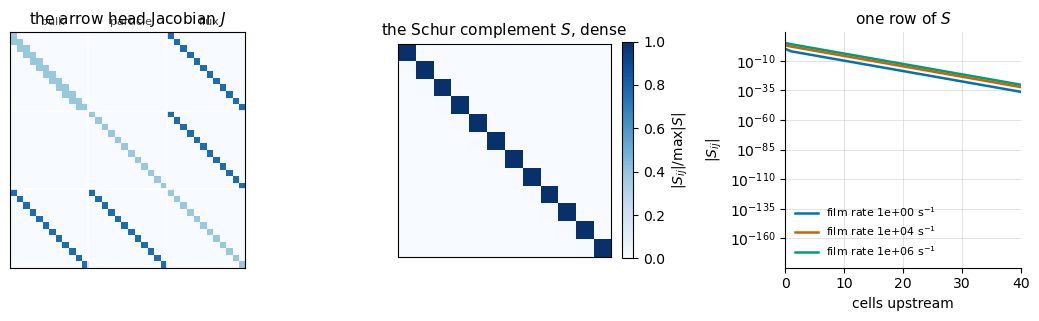

In [1]:
import utility.cadet_runtime as cadet_runtime
import utility.gmres_explorer as study

cadet_runtime.configure()

study.plot_arrow_head();

The right panel is the thing to keep hold of. For the lumped rate model with
pores the flux unknown is simply $j_f = c - c_p$, so $J_f = I$, $J_{f,0} = -I$
and $J_{f,p} = +I$, and the whole film coefficient sits in the two arms
(`residualFlux` in `LumpedRateModelWithPores.cpp`). What is left is

$$
S \;=\; I \;+\; a_c\,J_0^{-1} \;+\; a_p \left[J_p^{-1}\right]_{c_p c_p},
\qquad
a_c = \frac{3 k_f}{r_p}\frac{1-\varepsilon_c}{\varepsilon_c},
\qquad
a_p = \frac{3 k_f}{\varepsilon_p r_p}.
$$

**The film coefficient multiplies everything that makes $S$ differ from the
identity.** At $k_f \to 0$ the Schur complement *is* the identity and GMRES is
done in one iteration. Every decade of $k_f$ pushes it one decade further away.

That is the quantity this notebook keeps coming back to, so it has a name: the
**film rate** $a_c$, in $\mathrm{s^{-1}}$, next to which the other rate in the
problem is convection across one of 500 cells, about $6\ \mathrm{s^{-1}}$.

## 2. What GMRES actually does

GMRES builds the Krylov space

$$
\mathcal{K}_k = \operatorname{span}\{r_0,\; S r_0,\; S^2 r_0,\; \dots,\; S^{k-1} r_0\}
$$

one vector at a time (Arnoldi), and at every step takes the correction out of
that space which **minimizes the residual**. Three consequences of how it does
that, and then the test it stops on; the four settings come out of those.

**It costs one matrix-vector product and $k$ inner products per iteration.**
The new vector has to be orthogonalized against the whole basis so far. So $m$
iterations cost $m$ applications of $S$ but $\tfrac{1}{2}m^2$ inner products
and $m$ stored vectors. *Linear in work that you can see, quadratic in work
that you cannot.* This is what `MAX_KRYLOV` bounds.

**The residual it reports is an estimate.** It is not computed from the
solution; it is carried along in the Hessenberg factorization, and in finite
precision it drifts away from the true residual. A restart throws the basis
away and recomputes the real residual from scratch. That is the second thing
`MAX_RESTARTS` buys, besides bounding the work.

**It is unpreconditioned.** `Gmres.cpp:80` constructs
`SUNLinSol_SPGMR(..., SUN_PREC_NONE, ...)`. There is no preconditioner to
absorb a badly scaled $S$; the iteration count is whatever the matrix makes it.

### The stopping test

This is where the setting that matters lives. From
`LumpedRateModelWithPores-LinearSolver.cpp:242`:

```cpp
const double tolerance = std::sqrt(static_cast<double>(numDofs())) * outerTol * _schurSafety;
```

and the test inside SPGMR is on the **weight-scaled residual 2-norm against
that absolute number**. Three things to notice.

- `outerTol` is what IDAS asks of this Newton step. CADET registers its own
  linear solver and then calls `IDASetEpsLin(1)` and `IDASetLSNormFactor(1)`
  (`SimulatorImpl.cpp`), so IDAS scales nothing down and `outerTol` is the
  Newton convergence coefficient itself, $0.33$. **The tolerance is already
  tied to the integrator's own accuracy requirement before `SCHUR_SAFETY` is
  applied.**
- `SCHUR_SAFETY` is then a pure multiplier on top of that, and it defaults to
  $10^{-8}$. It is asking the linear solve for eight decades more than the
  Newton iteration that consumes it will use.
- The weights are the IDAS error weights, $w_i = 1/(r_{tol}|j_f| + a_{tol})$.

Because the test is absolute, what GMRES has to deliver is not a residual but
a **reduction**: $\text{tolerance} / \lVert w \circ r_0\rVert$. Run the real
Schur complement of this case and ask for different ones.

,required reduction,matrix-vector products,inner products
0,1e-06,9,45
1,1e-12,18,171
2,1e-16,23,276
3,1e-17,503,125256


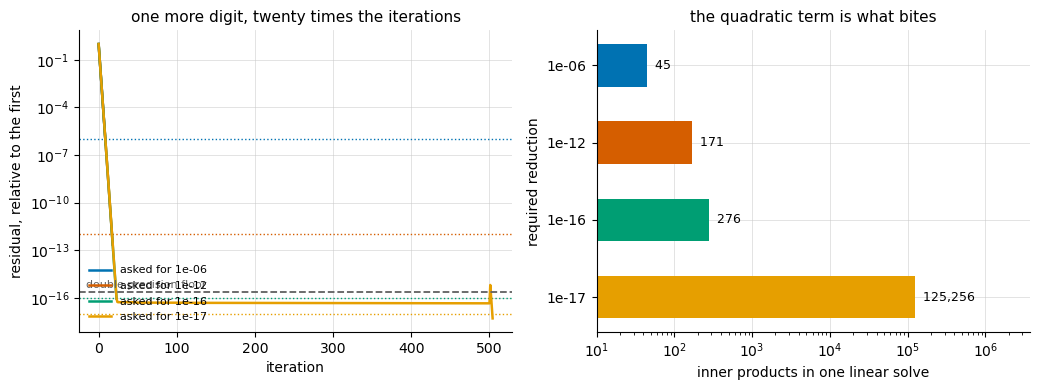

In [2]:
figure, axes, table = study.plot_residual_history()
table

Ten decades of extra accuracy cost fourteen extra iterations: 9 of them to
reduce the residual by $10^{-6}$, 23 to reduce it by $10^{-16}$. The eleventh
decade costs **four hundred and eighty**, and the inner products — the
quadratic term, the one that is not in the iteration count — go up by a factor
of 450.

## 3. The cliff is double precision

That jump is not a gradual loss of conditioning. It is a wall, and it is
always in the same place.

A residual is a difference of numbers of size $\lVert S\rVert \lVert x\rVert$.
Once the reduction demanded falls below about machine epsilon,
$2.2 \times 10^{-16}$, **no iteration count can deliver it**: the remaining
digits were lost to rounding before the iteration started. GMRES then has no
stopping criterion it can satisfy, so it builds Krylov vectors until the space
is exhausted or the restart budget runs out, every single time it is called.

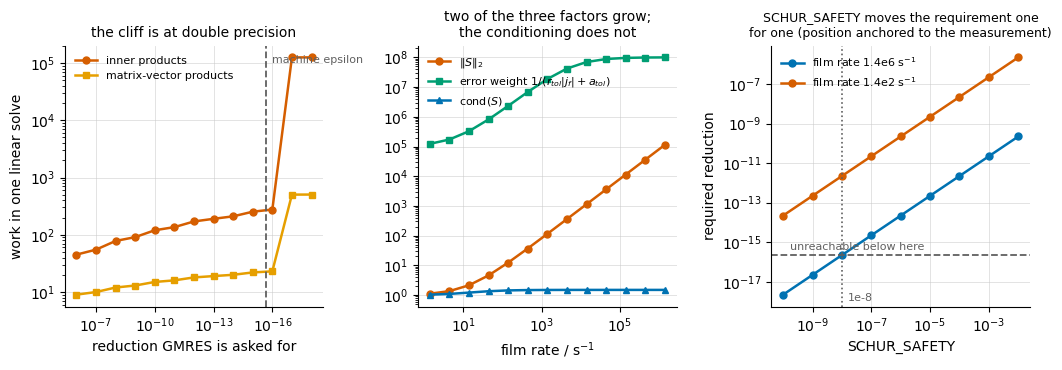

In [3]:
figure, axes, table = study.plot_cost_vs_reduction()

The middle panel says which knobs push a solve towards that wall, and it is
worth reading carefully because the obvious suspect is innocent.

| factor | how it moves with the film rate | why |
|---|---|---|
| $\lVert S \rVert$ | $\propto k_f$ | the film coefficient multiplies everything off the identity |
| error weight $w$ | grows, then saturates at $1/\texttt{ABSTOL}$ | $j_f = c - c_p$ is driven to zero, so $r_{tol}\lvert j_f\rvert$ falls below $a_{tol}$ |
| $\operatorname{cond}(S)$ | **flat, about 1.5** | — |

**The conditioning never degrades.** $S$ is a well-behaved matrix at every
film rate; GMRES solves it to a *relative* $10^{-8}$ in a dozen iterations
whatever $k_f$ is. What changes is the number of digits it is asked for, and
that is a product of three independent things — `SCHUR_SAFETY`, the norm of
$S$, and the error weight — of which the user controls one directly.

The right panel is the practical statement: `SCHUR_SAFETY` moves the
requirement one decade for one decade, and the default spends eight of them
before the model has said anything.

> **What is model and what is measurement.** The Schur complement above is
> built from the blocks CADET assembles, with a first order upwind bulk
> operator (the WENO stencil in the smooth limit) and the measured average BDF
> coefficient. It takes one component, because components do not couple in the
> bulk operator and the real $1000 \times 1000$ Schur complement is two
> independent copies of this one.
>
> One thing in it is not derivable from the source: how large the Newton
> residual is at the moment the linear solve is called. It multiplies the
> initial residual directly, so the model gives the *slope* of the requirement
> but not its absolute position. The right panel is therefore **anchored** —
> one constant, fitted once, so that `SCHUR_SAFETY = 1e-8` lands exactly on
> machine epsilon, which is where section 5 measures the cliff to be.
>
> Everything else is the model's own, including a prediction worth checking:
> at a film rate of $1.4 \times 10^{2}\ \mathrm{s^{-1}}$ the same curve sits
> four decades above the floor, so that case should be nowhere near the cliff
> at any sane `SCHUR_SAFETY`. The film sweep below runs it in 8 s.

## 4. The case

Two models, set up to be the same problem. That is the whole premise of the
comparison, and it is what makes the cost difference a pure solver artefact.

| | LRM | LRMP |
|---|---|---|
| porosity | total 0.72 | bed 0.3 $\times$ particle 0.6 = the same 0.72 |
| binding | linear, rapid equilibrium | identical |
| axial dispersion | 0 | 0 |
| film | — | $k_f = 1$ m/s at $r_p = 5\ \mu$m |
| grid | 500 FV cells, WENO | identical |
| unknowns | 2002 | 4002 |
| linear solve | banded factorization | arrow head $+$ GMRES on a $1000 \times 1000$ Schur complement |

$k_f = 1$ m/s is not a physical film coefficient. It is a deliberately enormous
one, chosen so that the pore liquid is pinned to the bulk liquid and the LRMP
*reduces* to the LRM. It puts the film rate at $1.4 \times 10^{6}\
\mathrm{s^{-1}}$, against convection at $6\ \mathrm{s^{-1}}$.

The measurement below runs every configuration in this notebook once and caches
the result. The full set takes about half an hour; `force=True` repeats it.

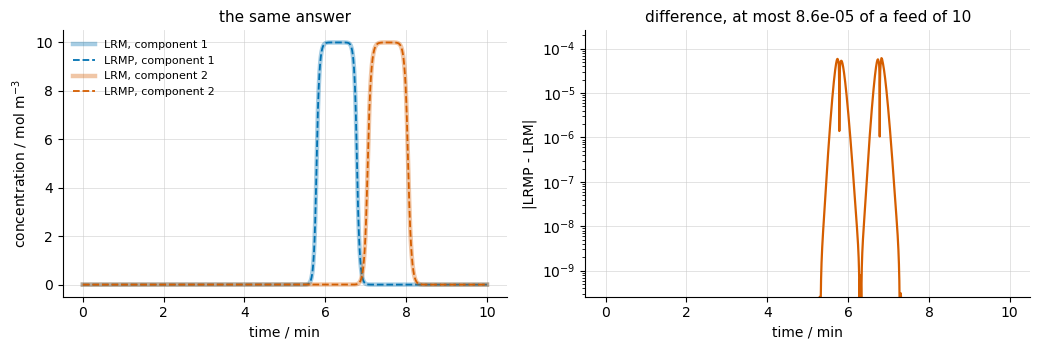

In [4]:
runs, curves = study.measure()

study.plot_same_problem();

The two chromatograms agree to about $10^{-5}$ of a feed of 10. **Whatever
costs the factor is not producing a different answer.** So look at what the
integrator did with it.

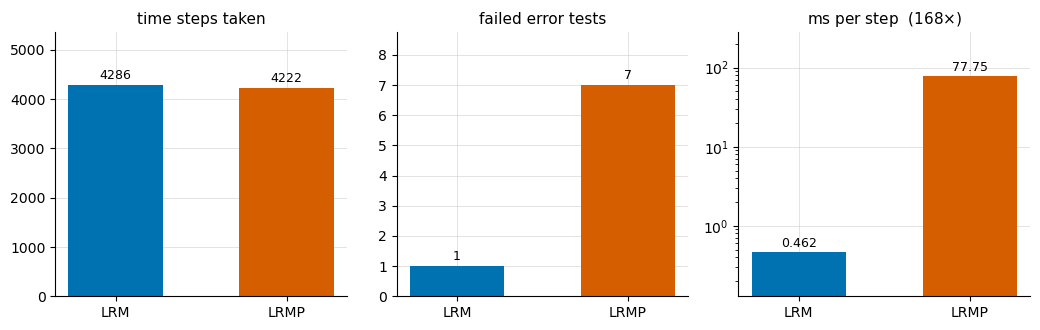

In [5]:
study.plot_where_the_time_goes();

**Not stiffness, and not size.** The LRMP takes *fewer* steps than the LRM, at
the same order, with a comparable number of failed error tests. The integrator
never noticed anything. The entire gap is cost per step, against 1.5 times the
unknowns.

Sweep the film coefficient and the shape of section 3 appears in the wall
clock.

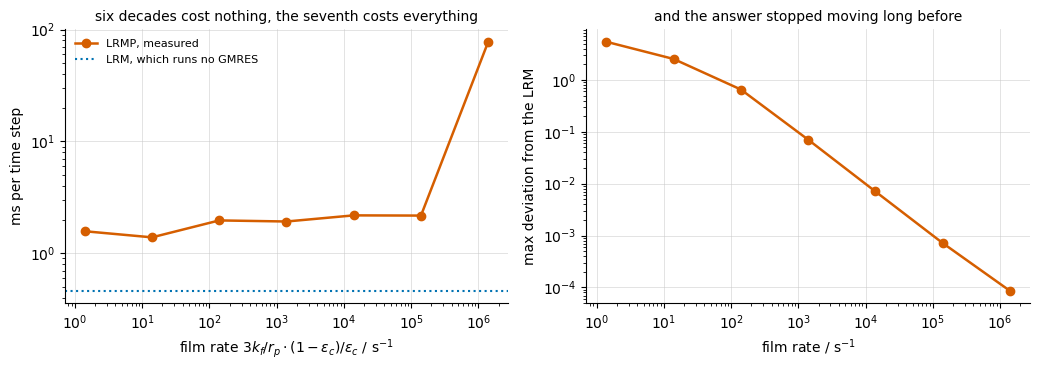

In [6]:
study.plot_the_cliff();

Six decades of film rate cost essentially nothing. The seventh costs a factor
of forty. And the right panel is the part worth taking personally: **the answer
stopped moving at a film rate of about $10^{4}\ \mathrm{s^{-1}}$**, two decades
before the cliff. Everything past that was paying for digits that had already
converged.

## 5. The four settings, measured

Every run below is the identical model. Only the configuration of the GMRES
changes — and, with one instructive exception, every one of them returns the
same answer.

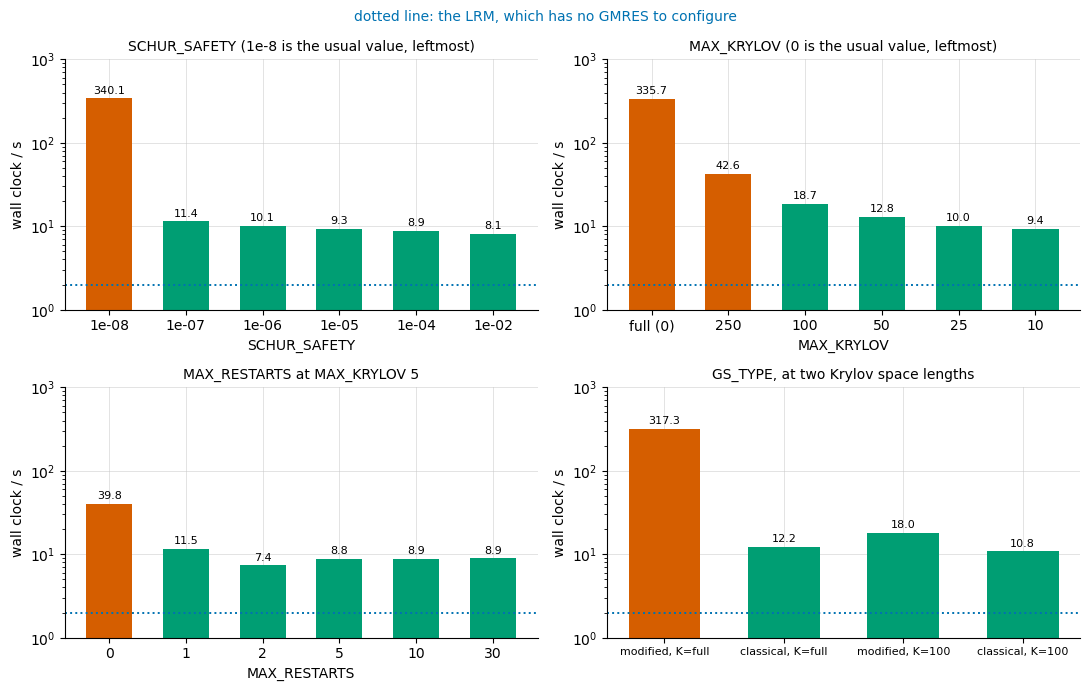

In [7]:
study.plot_parameter_sweeps();

In [8]:
study.summary()

,group,setting,GS_TYPE,MAX_KRYLOV,MAX_RESTARTS,SCHUR_SAFETY,wall clock / s,vs LRM,steps,max deviation from LRM
0,baseline,"LRM (no particles, no GMRES)",1,0,10,1e-08,1.98,1.0,4286,0.000e+00
1,baseline,"LRMP, default settings",1,0,10,1e-08,328.27,165.8,4222,8.636e-05
2,baseline,"LRMP, global sparse solver",1,0,10,1e-08,7.32,3.7,4524,9.757e-05
3,schur_safety,1e-08,1,0,10,1e-08,340.12,171.8,4222,8.636e-05
4,schur_safety,1e-07,1,0,10,1e-07,11.42,5.8,4222,8.636e-05
5,schur_safety,1e-06,1,0,10,1e-06,10.07,5.1,4222,8.636e-05
6,schur_safety,1e-05,1,0,10,1e-05,9.34,4.7,4222,8.636e-05
7,schur_safety,1e-04,1,0,10,1e-04,8.87,4.5,4222,8.636e-05
8,schur_safety,1e-02,1,0,10,1e-02,8.10,4.1,4313,8.643e-05
9,max_krylov,full (0),1,0,10,1e-08,335.69,169.5,4222,8.636e-05


### `SCHUR_SAFETY` — the sharpest of the four

A multiplier on a tolerance that was already appropriate, and it moves the
required reduction one decade for one decade. **One single decade is the whole
cliff here**: `1e-8` costs 340 s, `1e-7` costs 11.4 s. That is what a threshold
at machine epsilon looks like from the outside — not a slope you tune along,
a wall you are either behind or in front of.

Everything beyond that first decade is ordinary diminishing returns: 10.1 s at
`1e-6`, 8.9 s at `1e-4`, 8.1 s at `1e-2`.

Loosening it does **not** loosen the simulation's accuracy. The deviation from
the LRM is `8.636e-05` for every row from `1e-8` to `1e-2` — the same number to
four digits. The integrator's error control is untouched; all that changes is
how precisely each Newton correction is computed, and a Newton iteration
converging quadratically does not need the eighth digit of its own correction.

The risk of going too far is real, and the table shows you where it starts: at
`1e-2` the step count rises from 4222 to 4313. That is the signal. **Watch the
step count, not the answer** — the corrections degrade long before the result
does, and the integrator pays for it in extra steps.

### `MAX_KRYLOV` — the quadratic term

The number of Krylov vectors per cycle. `0` means *the full size of the Schur
complement*, here 1000 (`Gmres.cpp:70`) — the usual value, and the most
expensive thing it could mean. Two costs grow with it:

,MAX_KRYLOV,matrix-vector products,inner products,restart cycles used,converged,basis vectors stored
0,10,25,125,2,True,11
1,25,28,331,1,True,26
2,50,53,1281,1,True,51
3,100,103,5056,1,True,101
4,250,253,31381,1,True,251
5,500,503,125256,1,True,501


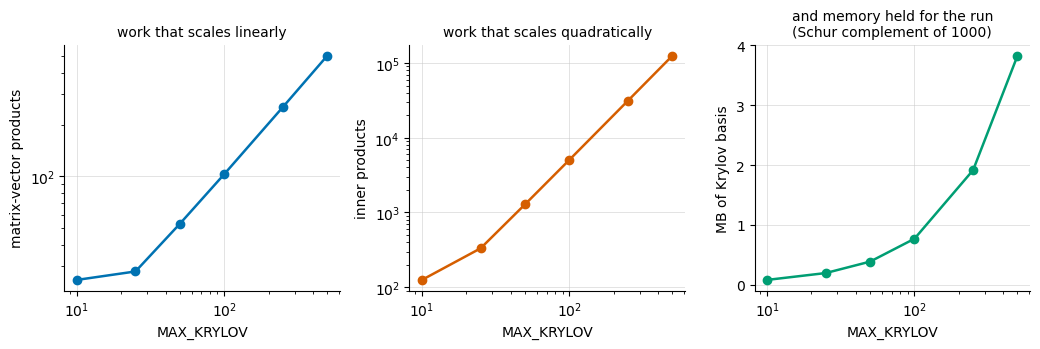

In [9]:
figure, axes, table = study.plot_krylov_cost()
table

At a requirement past the floor, a Krylov space of 10 solves the system in 125
inner products and a Krylov space of 500 takes 125 256 — a factor of a
thousand, for the same matrix and the same answer.

The short space wins twice, and the second reason is the interesting one. In
one long cycle the carried-along residual estimate **stalls**: after about 25
iterations it stops at $1.1 \times 10^{-10}$ and stays there, and by then it is
optimistic by a factor of six against the true residual. The iteration cannot
stop, so it keeps building vectors. Restarting from a freshly computed true
residual every 10 iterations converges in 25 matrix-vector products total.
`MAX_KRYLOV` is not only a cost cap; on a stalled solve it is what makes the
iteration work at all.

The memory panel is the other half of the default. `MAX_KRYLOV = 0` allocates
`MAX_KRYLOV + 1` vectors of the Schur complement size for the whole run — 8 MB
here, and it grows with the square of the grid refinement.

Measured, on the case, at the usual `SCHUR_SAFETY`: **336 s** at `0`, 42.6 s
at 250, 18.7 s at 100, 12.8 s at 50, 10.0 s at 25, 9.4 s at 10. Same answer in
every row.

Off the cliff, none of this matters: GMRES converges in a couple of dozen
iterations and every `MAX_KRYLOV` above that is identical. **`MAX_KRYLOV` is
insurance against a solve going wrong, not a tuning parameter for one that is
going right** — but it is insurance that costs nothing to hold.

### `MAX_RESTARTS` — the budget, and a silent failure

How many times GMRES may throw the basis away and start again. It only does
anything once `MAX_KRYLOV` is too short to finish inside one cycle. At
`MAX_KRYLOV = 25`, where the solve finishes in the first cycle, the measured
sweep from 0 to 30 restarts is **completely flat** — 9.7 to 10.3 s, 4222 steps,
the same answer, every row.

So force the issue: set `MAX_KRYLOV = 5`, where one cycle is not enough. The
model problem first, to see what the solver is handing back:

In [10]:
study.restart_cost()

,MAX_RESTARTS,matrix-vector products,inner products,cycles used,converged,residual reached
0,0,5,15,0,False,6.18e+02
1,1,10,30,1,False,1.89e-01
2,2,15,45,2,False,5.88e-05
3,5,23,66,4,True,1.43e-10
4,10,23,66,4,True,1.43e-10
5,30,23,66,4,True,1.43e-10


Denied its restarts, GMRES does not fail. It **returns** — with a residual of
618 where 1e-10 was asked for, at zero restarts, and 5.9e-5 at two. And nothing
upstream is told. On the **system** level,
`ModelSystemImpl-LinearSolver.cpp` feeds the GMRES return flag into the error
indicator and the time integrator finds out. On the **unit operation** level it
does not: `LumpedRateModelWithPores::linearSolve` discards the flag from
`_gmres.solve` and returns success unconditionally, and so do the GRM variants.

Here is what that costs in the real simulation, at the same `MAX_KRYLOV = 5`:

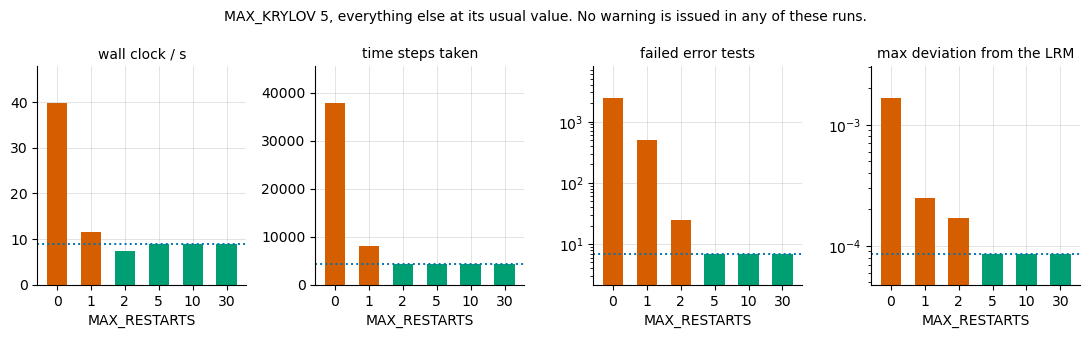

In [11]:
study.plot_silent_failure();

**Nine times the time steps, 350 times the failed error tests, and an answer
twenty times further from the reference — and not one line of output saying
so.** The integrator is handed corrections that are wrong, rejects steps,
shrinks the step size, and grinds its way to an answer it has no reason to
distrust. Every number in that figure is the sound a silent failure makes.

Two restarts is already nearly enough; five is indistinguishable from thirty.
`MAX_RESTARTS` is a *limit*, not a count, so it is cheap to leave generous.

**It is not a safety net, though, and that is the point.** Lowering it does not
make a solve fail safely, it makes it fail invisibly. Leave it at 10 or raise
it; if the work needs bounding, bound `MAX_KRYLOV` instead, which caps the cost
*and* keeps the solve converging.

### `GS_TYPE` — the one nobody expects

How the new Krylov vector is orthogonalized against the basis. Both variants do
the same $k+1$ inner products, so an operation count cannot tell them apart:

In [12]:
study.gram_schmidt_quality()

,orthogonalization,iterations,inner products,passes over the basis,reorthogonalizations triggered
0,"GS_TYPE 1, modified (default)",40,820,1640,0
1,"GS_TYPE 0, classical with reorthogonalization",40,820,80,0


What differs is how those inner products are organised, and the last column is
the whole story. **Modified** (`GS_TYPE = 1`, the usual value) subtracts one
basis vector at a time: $2(k+1)$ traversals of the basis, strictly in sequence,
nothing to vectorize. **Classical** (`GS_TYPE = 0`) does one fused multi-dot
and one linear combination: two traversals whatever $k$ is. At $k = 40$ that is
1640 passes against 80, and the ratio grows linearly with the Krylov space.

Which, on a Krylov space of 1000, is worth this:

| | `MAX_KRYLOV = 0` (1000) | `MAX_KRYLOV = 100` |
|---|---|---|
| `GS_TYPE = 1`, modified | **317 s** | 18.0 s |
| `GS_TYPE = 0`, classical | **12.2 s** | 10.8 s |

A factor of **26**, from a setting that changes no arithmetic result and that
the documentation describes in one line about Gram-Schmidt orthogonalization.
It is pure memory traffic, and it only appears because the cliff has driven the
Krylov space to a length where memory traffic is the entire cost.

Is classical safe? Its reputation for losing orthogonality is why modified is
the conventional choice, but SUNDIALS guards both variants at different
thresholds: `SUNClassicalGS` re-orthogonalizes whenever the first pass cost the
new vector more than three decades of norm, `SUNModifiedGS` only when it was
annihilated down to roundoff. Neither fires on this problem, and the two runs
agree to every digit of the answer.

**So `GS_TYPE = 0` is worth knowing about when the Krylov space is long** —
which, if you have got there, is itself the thing to fix.

## 6. How to choose the four

The four are not independent, and the case shows why. The cliff drives the
Krylov space long; a long Krylov space is what makes `MAX_KRYLOV` and
`GS_TYPE` expensive. So one cause, three places to intervene — and the usual
values happen to be the worst choice at all three.

| field | usual value | what it does | advice |
|---|---|---|---|
| `SCHUR_SAFETY` | `1e-8` | multiplies the tolerance that IDAS already set appropriately | **The first thing to change**, because it treats the cause. `1e-6` is a safe general setting: two decades of headroom, and it moved no digit of the answer here. Go further only while watching the step count. |
| `MAX_KRYLOV` | `0` (= the full Schur complement) | Krylov vectors per cycle; bounds the quadratic orthogonalization cost, the memory held for the run, and the damage a stalled solve can do | **Set it.** 25 to 100 is a cap rather than a constraint for a solve that is behaving, and worth a factor of thirty for one that is not. At `0` the Krylov basis also grows with the square of the refinement — 8 MB here. |
| `MAX_RESTARTS` | `10` | how many cycles before GMRES gives up — **silently**, on the unit operation level | Leave it, or raise it. Never lower it to save work: it does not make a solve fail safely, it makes it fail invisibly, and the bill arrives as time steps. |
| `GS_TYPE` | `1` (modified) | how the basis is orthogonalized: $2(k+1)$ sequential passes over it, or 2 fused ones | Irrelevant for a short Krylov space, worth a factor of 26 for a long one. If you are leaving `MAX_KRYLOV` at `0`, set this to `0` as well. |

### And the fifth setting, which is not in that group

`FV_ARROW_HEAD_OPTIMIZATION = 0` routes the same model through
`ColumnModel1D`'s global sparse solver, which factorizes the whole system
directly. No Schur complement, no iteration, none of the four settings, and no
sensitivity to how well conditioned anything is. On this case it is the fastest
of all. The arrow head solver is the better structure for most problems — it is
why it is the default — but when an FV model with particles is unaccountably
slow, this is the one-line test that tells you whether the linear solve is the
cause.

### Diagnosing it

The symptom has no signature in anything the integrator reports. Step counts,
BDF order, error test failures, residual calls: all normal. The recipe:

1. **Is cost per step high?** Run with `WRITE_IDAS_META = 1` and divide
   `meta/TIME_SIM` by the step count — `utility.stiffness_metrics.measure()`
   reads it, and it is worth using rather than taking
   `meta/idas/IDAS_NTIMESTEPS`, which CADET resets at every section transition
   and which therefore only holds the last section. If the step count is
   reasonable and the time is not, the problem is below the integrator.
2. **Does the unit run a GMRES at all?** FV, with particles, with
   `FV_ARROW_HEAD_OPTIMIZATION` at its default. If so,
3. **Set `FV_ARROW_HEAD_OPTIMIZATION = 0`.** If the model gets much faster, it
   was the iterative solve, and
4. **Set `SCHUR_SAFETY = 1e-6` and `MAX_KRYLOV = 50`**, then compare the
   answer and the step count. If neither has moved, keep them.

And before any of that: **check whether the parameter that drives the cost is
one you needed.** The right panel of section 4 says the answer had converged
two decades below the setting that caused the trouble. A film coefficient
chosen to make an LRMP behave like an LRM is a sign that the model wanted to be
an LRM.

### For CADET-Core

Four things in this notebook are conventions rather than physics:

- `SCHUR_SAFETY = 1e-8` on an unpreconditioned GMRES makes the cost of a
  well-posed model depend on a coupling coefficient, with a cliff rather than a
  warning, and the eight decades of slack bought nothing measurable on any run
  here.
- `MAX_KRYLOV = 0` means the longest and most memory-hungry Krylov space
  available — the worst choice for exactly the cases that need the setting.
- `GS_TYPE = 1` with `MAX_KRYLOV = 0` is a factor of 26 on this case. Whatever
  the right default for `GS_TYPE` is on its own, *that combination* should not
  be the one a user gets without asking.
- The unit operation level discarding the GMRES return flag turns a diagnosable
  failure into an unexplained slowdown — nine times the time steps, with no
  output. Logging it would cost nothing.

Preconditioning the Schur complement — the diagonal of $S$ alone would do a
lot, given its structure — would make all four of these settings matter much
less.

> **Take-away.** The stiffness chapter found that cost comes from accuracy,
> never from stability. This is a third source and it belongs on the list: the
> **cost of the linear solve inside each step**, which no step count, BDF order
> or error-test counter will reveal. When a model is slow and the integrator
> looks healthy, look below it.

## Summary

- Similar chromatograms and time integration step counts can hide significant differences in linear-solver computational cost.
- GMRES performance depends on residual reduction, finite-precision effects, orthogonalization cost, and restart behavior.
- The settings `SCHUR_SAFETY`, `MAX_KRYLOV`, `MAX_RESTARTS`, and `GS_TYPE` influence solver performance and robustness. Their effects should be evaluated using measured runtime and solution accuracy rather than assuming that stricter settings always lead to better results.

**Next:** Return to [**99.7g User Stories**](../99.7g_user_stories_lesson.ipynb) to explore another diagnostic case.